# 06 Planted-error test of our diagnostics (motor)

**Claim being tested** (AI_USE_LOG entry 28): errors in the frequency/severity assumptions shift the
*level* of whole years, while model errors distort *differences between segments* within a year.

**Method:** plant three known assumption errors and three known model errors, one at a time, and check
whether each diagnostic attributes them to the right side. Two validation folds: 2021–22 → 2023 (mature)
and 2021–23 → 2024 (immature).

| Case | Planted error | Expected side |
|---|---|---|
| A1 | own_damage severity trend 4% → 0% | target |
| A2 | 2024 completeness ignored (weight = exposure) | target |
| A3 | BI reform factor 0.83 → 1.0 | target |
| B1 | driver age features removed (driver_age, years_licensed, named_young_driver) | model |
| B2 | over-fitting: no regularisation, 30 bands | model |
| B3 | region removed | model |

In [1]:
import sys, copy, time
sys.path.append("..")
import numpy as np
import pandas as pd
from src.target import ADJ, load_policies, load_claims
from src.features import build_features
from src.diagnostics import run_case, summarise

claims = load_claims()
p = load_policies("motor", "train")
F = build_features("motor", "train", policies=p)
SEG = ["driver_age", "region", "vehicle_value_group", "cover_type", "new_business", "ncb_years", "credit_band"]

def adj_with(**changes):
    a = copy.deepcopy(ADJ["motor"])
    for k, v in changes.items():
        a[k].update(v)
    return a

CASES = {
    "baseline": {},
    "A1_no_od_trend": {"adj": adj_with(sev_trend={"own_damage": 0.0})},
    "A2_ignore_2024_immaturity": {"comp_2024_one": True},
    "A3_no_bi_reform": {"adj": adj_with(reform={"bodily_injury": 1.0})},
    "A4_no_freq_shift": {"adj": adj_with(freq_shift={"own_damage": 1.0, "third_party_prop": 1.0})},
    "B1_drop_driver_age": {"drop_features": ("driver_age", "years_licensed", "named_young_driver")},
    "B2_overfit": {"glm_kwargs": {"alpha": 1e-8, "n_bands": 30, "min_frequency": 1e-4}},
    "B3_drop_region": {"drop_features": ("region",)},
}
EXPECTED = {k: ("target" if k.startswith("A") else "model") for k in CASES if k != "baseline"}

## Run all cases
**Purpose:** each case rebuilds the target (if its assumptions change), fits the GLM on both folds and records
level error, shape error and the model-free checks. About 1–2 minutes per case.

In [2]:
results = []
for name, kw in CASES.items():
    t0 = time.time()
    results.append(run_case(name, claims, p, F, SEG, **kw))
    print(f"{name}: done in {time.time() - t0:.0f}s")

baseline: done in 63s
A1_no_od_trend: done in 61s
A2_ignore_2024_immaturity: done in 61s
A3_no_bi_reform: done in 64s
A4_no_freq_shift: done in 61s
B1_drop_driver_age: done in 59s
B2_overfit: done in 66s
B3_drop_region: done in 61s


## Results
**Level error** = |log A/E| on the validation years + tilt of A/E across training years.
**Shape error** = spread of log A/E across segments within the validation year.
`d_level` and `d_shape` are changes against the baseline; the signature rule says *target* when the level
change is larger, *model* when the shape change is larger.

In [3]:
t = summarise(results)
pd.set_option("display.width", 200)
print(t[["AE_2023", "AE_2024", "D2_2023", "D2_2024", "level_err", "shape_err", "d_level", "d_shape",
         "worst_segment_2024"]].round(4))

                           AE_2023  AE_2024  D2_2023  D2_2024  level_err  shape_err  d_level  d_shape worst_segment_2024
case                                                                                                                    
baseline                    1.0437   1.0246   0.0477   0.0517     0.0522     0.0435   0.0000   0.0000             region
A1_no_od_trend              1.0528   1.0374   0.0469   0.0508     0.0647     0.0449   0.0124   0.0014         cover_type
A2_ignore_2024_immaturity   1.0437   0.8361   0.0477   0.0479     0.1296     0.0435   0.0774   0.0000             region
A3_no_bi_reform             0.9709   0.9814   0.0472   0.0518     0.0334     0.0461  -0.0189   0.0026         cover_type
A4_no_freq_shift            1.0121   1.0075   0.0485   0.0521     0.0243     0.0428  -0.0279  -0.0007             region
B1_drop_driver_age          1.0339   0.9974   0.0424   0.0441     0.0277     0.0539  -0.0246   0.0104         driver_age
B2_overfit                  1.06

In [4]:
diag = ["signature_rule", "diag1_target_check", "diag2_freq_sev", "diag3_mature_year", "diag4_train_vs_valid"]
score = t.drop(index="baseline")[diag].copy()
score.insert(0, "expected", pd.Series(EXPECTED))
print(score)
print("\ncorrect attributions per diagnostic:")
for d in diag:
    ok = [EXPECTED[c] in score.loc[c, d] for c in score.index]
    print(f"  {d}: {sum(ok)}/{len(ok)}")

                          expected signature_rule diag1_target_check     diag2_freq_sev    diag3_mature_year diag4_train_vs_valid
case                                                                                                                             
A1_no_od_trend              target         target              model  target (severity)                model               target
A2_ignore_2024_immaturity   target         target             target              model  target (immaturity)               target
A3_no_bi_reform             target          model             target  target (severity)               target               target
A4_no_freq_shift            target          model             target  target (severity)               target               target
B1_drop_driver_age           model          model              model              model  target (immaturity)    model (structure)
B2_overfit                   model         target              model              model   

Matplotlib is building the font cache; this may take a moment.


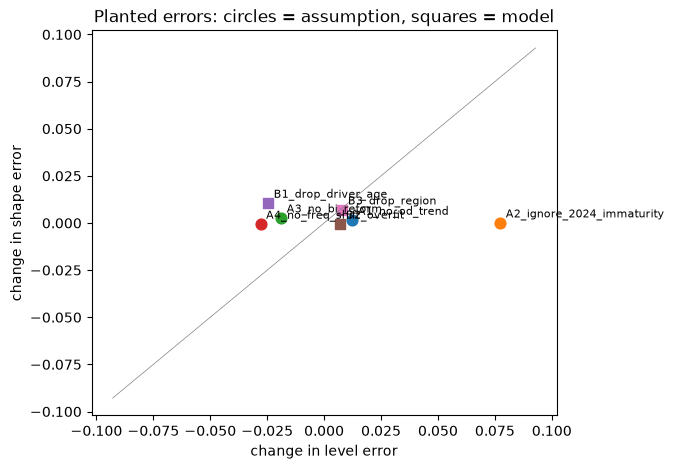

In [5]:
# Level vs shape changes (one point per case)
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 5))
    s = t.drop(index="baseline")
    for c in s.index:
        ax.scatter(s.loc[c, "d_level"], s.loc[c, "d_shape"], marker="o" if c.startswith("A") else "s", s=60)
        ax.annotate(c, (s.loc[c, "d_level"], s.loc[c, "d_shape"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    lim = max(s[["d_level", "d_shape"]].abs().max()) * 1.2
    ax.plot([-lim, lim], [-lim, lim], lw=0.5, color="grey")
    ax.set_xlabel("change in level error"); ax.set_ylabel("change in shape error")
    ax.set_title("Planted errors: circles = assumption, squares = model")
    plt.show()
except ImportError:
    print("matplotlib not installed: pip install matplotlib")